In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# loading predictions handoff file
df = pd.read_csv("data/predictions_for_analysis.csv")

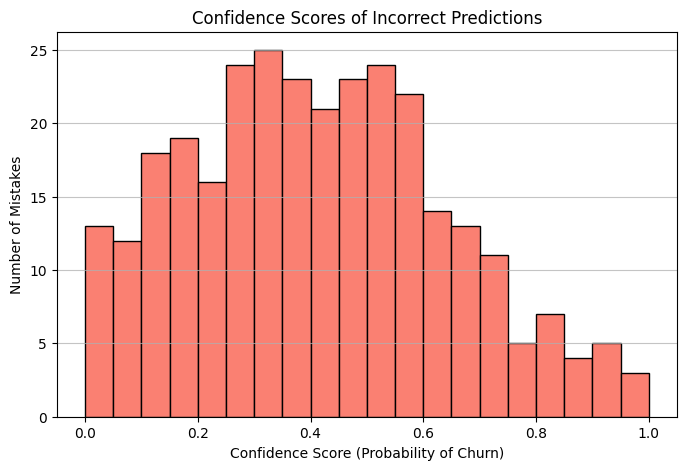

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Load the predictions file
df = pd.read_csv('data/predictions_for_analysis.csv')

# 2. Isolate only the rows where the model guessed wrong
errors = df[df['True_Label'] != df['Predicted_Label']]

# 3. Plot how confident the model was when making those mistakes
plt.figure(figsize=(8, 5))
plt.hist(errors['Confidence_Score'], bins=20, color='salmon', edgecolor='black')
plt.title('Confidence Scores of Incorrect Predictions')
plt.xlabel('Confidence Score (Probability of Churn)')
plt.ylabel('Number of Mistakes')
plt.grid(axis='y', alpha=0.75)
plt.show()


In [1]:
import pandas as pd

df = pd.read_csv('data/predictions_for_analysis.csv')
print('Rows:', len(df))
print('Errors:', (df['True_Label'] != df['Predicted_Label']).sum())

Rows: 1407
Errors: 302


In [3]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(df['True_Label'], df['Predicted_Label'])
print("Confusion Matrix:")
print(cm)
print("\nTrue Negatives (0 -> 0):", cm[0, 0])
print("False Positives (0 -> 1):", cm[0, 1])
print("False Negatives (1 -> 0):", cm[1, 0])
print("True Positives (1 -> 1):", cm[1, 1])

Confusion Matrix:
[[927 106]
 [196 178]]

True Negatives (0 -> 0): 927
False Positives (0 -> 1): 106
False Negatives (1 -> 0): 196
True Positives (1 -> 1): 178


In [4]:
# Create a binary error flag: 1 if wrong, 0 if right
df['is_error'] = (df['True_Label'] != df['Predicted_Label']).astype(int)

# Compute correlation with is_error and sort by strongest magnitude
corrs = df.corr()['is_error'].drop('is_error')
top_corrs = corrs.reindex(corrs.abs().sort_values(ascending=False).index).head(10)

print("Top 10 features correlated with errors:")
print(top_corrs)

Top 10 features correlated with errors:
True_Label                              0.453469
Confidence_Score                        0.280095
Contract_Two year                      -0.261547
tenure                                 -0.219201
Predicted_Label                         0.194257
PaymentMethod_Electronic check          0.193862
StreamingTV_No internet service        -0.178720
InternetService_No                     -0.178720
DeviceProtection_No internet service   -0.178720
OnlineBackup_No internet service       -0.178720
Name: is_error, dtype: float64


In [5]:
from sklearn.ensemble import IsolationForest

# Use only input features (exclude target, prediction, confidence, and error flag)
exclude_cols = ['True_Label', 'Predicted_Label', 'Confidence_Score', 'is_error']
feature_cols = [c for c in df.columns if c not in exclude_cols]

iso = IsolationForest(contamination=0.05, random_state=42)
# IsolationForest returns -1 for outliers and 1 for normal points
df['is_outlier'] = (iso.fit_predict(df[feature_cols]) == -1).astype(int)

print("Error rate on normal points:", df[df['is_outlier'] == 0]['is_error'].mean())
print("Error rate on outliers:      ", df[df['is_outlier'] == 1]['is_error'].mean())
print("Total outliers flagged:      ", df['is_outlier'].sum())

Error rate on normal points: 0.22080838323353294
Error rate on outliers:       0.09859154929577464
Total outliers flagged:       71


In [6]:
# 1. Slice by Contract_Two year (0 = not a two-year contract, 1 = two-year contract)
print("Error rate by Two-Year Contract:")
print(df.groupby('Contract_Two year')['is_error'].agg(['count', 'mean']))

# 2. Slice by tenure buckets (short vs. medium vs. long tenure)
tenure_slice = pd.cut(df['tenure'], bins=[-1, 12, 36, 100], labels=['0-12m', '13-36m', '37m+'])
print("\nError rate by Tenure group:")
print(df.groupby(tenure_slice, observed=False)['is_error'].agg(['count', 'mean']))

Error rate by Two-Year Contract:
                   count      mean
Contract_Two year                 
False               1069  0.275023
True                 338  0.023669

Error rate by Tenure group:
        count      mean
tenure                 
0-12m     411  0.299270
13-36m    393  0.259542
37m+      603  0.127695


In [7]:
total_rows = len(df)
total_errors = df['is_error'].sum()
accuracy = 1 - (total_errors / total_rows)
high_conf_errors = ((df['is_error'] == 1) & (df['Confidence_Score'] > 0.80)).sum()

print("=== ML MODEL FAILURE REPORT ===")
print(f"Total Test Samples:       {total_rows}")
print(f"Overall Accuracy:         {accuracy:.2%}")
print(f"Total Errors:             {total_errors} ({total_errors / total_rows:.2%})")
print(f"False Negatives (Missed): {cm[1, 0]}")
print(f"False Positives:          {cm[0, 1]}")
print(f"High-Conf Errors (>0.80): {high_conf_errors}")
print("\nKey Takeaways:")
print("- Model misses over half of actual churners (False Negatives > False Positives).")
print("- Errors are much higher on non-two-year contracts (~27.5%) and 0-12m tenure (~29.9%).")
print("- Flagged outliers (IsolationForest) do not drive a higher error rate than normal rows.")

=== ML MODEL FAILURE REPORT ===
Total Test Samples:       1407
Overall Accuracy:         78.54%
Total Errors:             302 (21.46%)
False Negatives (Missed): 196
False Positives:          106
High-Conf Errors (>0.80): 19

Key Takeaways:
- Model misses over half of actual churners (False Negatives > False Positives).
- Errors are much higher on non-two-year contracts (~27.5%) and 0-12m tenure (~29.9%).
- Flagged outliers (IsolationForest) do not drive a higher error rate than normal rows.
